In [1]:
import sys

sys.path.append("../src")

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from solvers.lbm import cylinder_mask, equilibrium, macroscopic, run, step

In [3]:
# --- Re = 20: should converge to a steady flow with two vortices ---
rho, u, mask = run(Re=20, n_steps=40_000)
speed = np.hypot(u[0], u[1])

step 500: max change 1.06e-01
step 1000: max change 4.52e-02
step 1500: max change 2.48e-02
step 2000: max change 1.70e-02
step 2500: max change 1.23e-02
step 3000: max change 9.46e-03
step 3500: max change 7.53e-03
step 4000: max change 3.01e-03
step 4500: max change 5.63e-04
step 5000: max change 3.61e-04
step 5500: max change 1.91e-04
step 6000: max change 9.49e-05
step 6500: max change 4.63e-05
step 7000: max change 3.45e-05
step 7500: max change 2.08e-05
step 8000: max change 1.00e-05
step 8500: max change 6.25e-06
step 9000: max change 5.85e-06
step 9500: max change 3.44e-06
step 10000: max change 2.34e-06
step 10500: max change 2.13e-06
step 11000: max change 1.52e-06
step 11500: max change 7.75e-07


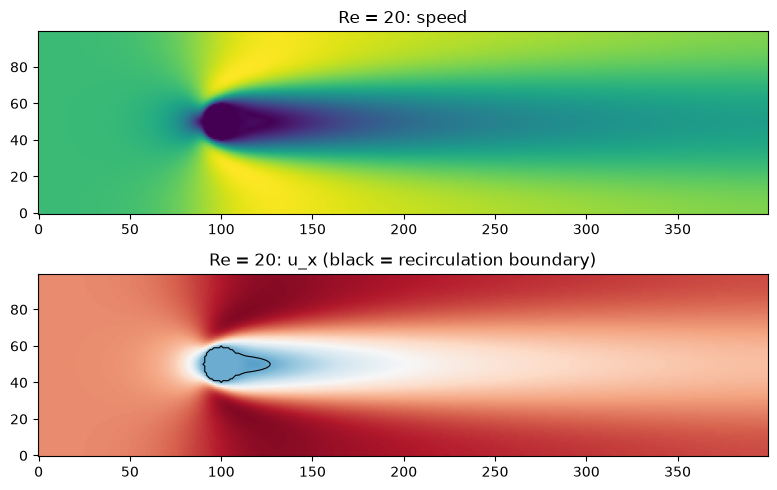

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].imshow(speed, origin="lower", cmap="viridis")
axes[0].set_title("Re = 20: speed")
axes[1].imshow(u[0], origin="lower", cmap="RdBu_r", vmin=-0.05, vmax=0.15)
axes[1].contour(
    u[0], levels=[0], colors="k", linewidths=0.8
)  # u_x = 0 outlines the recirculation
axes[1].set_title("Re = 20: u_x (black = recirculation boundary)")
plt.tight_layout()
plt.show()

In [ ]:
# --- Re = 100: should shed vortices, so track u_y at a probe behind the cylinder ---
Nx, Ny, D, Re, u_in = 400, 100, 20, 100, 0.1
tau = 3 * (u_in * D / Re) + 0.5
mask = cylinder_mask(Ny, Nx, cx=Nx // 4, cy=Ny // 2, r=D / 2)
rho = np.ones((Ny, Nx))
u = np.zeros((2, Ny, Nx))
u[0] = u_in
u[1] += 1e-3 * np.sin(2 * np.pi * np.arange(Nx) / Nx)
f = equilibrium(rho, u)

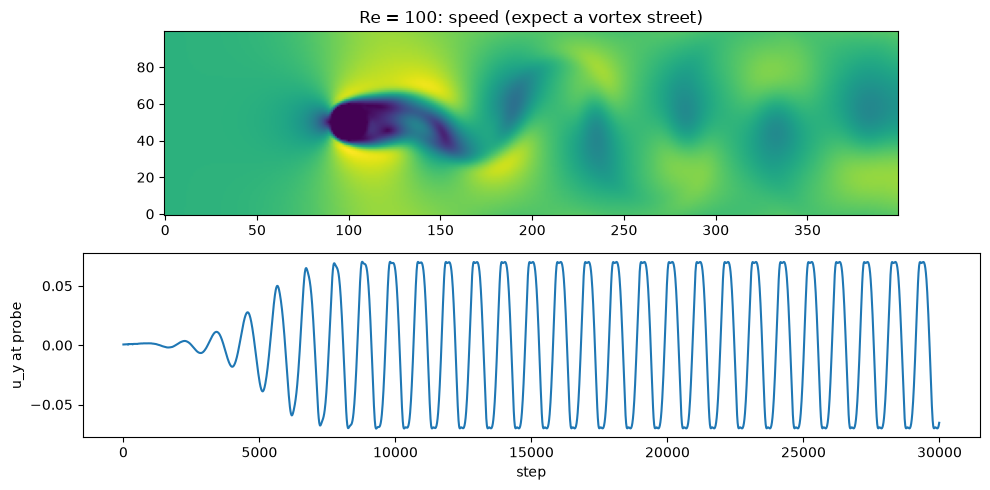

In [ ]:
probe = (Ny // 2, Nx // 4 + 3 * D)  # 3 diameters downstream, on the centreline
uy_probe = []
for t in range(30_000):
    f = step(f, tau, mask, u_in)
    if t % 10 == 0:
        uy_probe.append(macroscopic(f)[1][1][probe])

rho, u = macroscopic(f)
u[:, mask] = 0
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].imshow(np.hypot(u[0], u[1]), origin="lower", cmap="viridis")
axes[0].set_title("Re = 100: speed (expect a vortex street)")
axes[1].plot(np.arange(len(uy_probe)) * 10, uy_probe)
axes[1].set_xlabel("step")
axes[1].set_ylabel("u_y at probe")
plt.tight_layout()
plt.show()